# 阶段 2 · 第 1 课：数一数，就能编名字

从这一课开始做**语言模型**。ChatGPT 这类大模型，说到底只做一件事：**给前面的字，猜下一个字**（准确说是下一个 token，阶段 3 讲）。一整段回答，就是这样一个字一个字猜出来的。

这一课用最简单的办法做一个语言模型：**数数**。数据是 32,033 个英文名字，模型学完以后自己编新名字。

**终点预告**：这一课结束时，你的程序会编出这样的名字：

```
cexze
momasurailezitynn
konimittain
llayn
ka
```

有的挺像名字，有的很离谱，而且没有一个是数据里原有的：模型真的在「编」。你还会算出一个数：**2.45**。它说明模型猜得有多准，越小越好；完全瞎猜是 3.30。

一共 7 小步，每一步都先碰到一个麻烦，再解决它：

| 小步 | 上一步留下的麻烦 | 这一步的办法 | 你填的 TODO |
|---|---|---|---|
| 1 | 还不知道语言模型要做什么 | 读数据，看一个名字是怎么一个字母一个字母「猜」出来的 | 无 |
| 2 | 先试最笨的办法 | 每个字母都随便挑 | 无 |
| 3 | 随便挑出来的全是乱码 | 数一数：每个字母后面通常跟着什么 | TODO 1 |
| 4 | 计数散在字典里，不好查，也看不清全貌 | 放进一张 27×27 的表 | TODO 2 |
| 5 | 次数还不是概率 | 每一行除以这一行的总和 | TODO 3 |
| 6 | 有了概率，还不会用 | 照概率一个一个抽字母，编名字 | TODO 4 |
| 7 | 编得好不好只能凭感觉 | 用一个数打分：loss | TODO 5 |

**怎么上**：`names.txt` 和这个笔记本放在同一个文件夹。从上往下 `Shift+Enter`，带 `TODO` 的格子先填好再运行。

**提示怎么用**：灰色的「▶ 提示」点开才显示。API 和写法直接写在格子上方；涉及概念的地方分几级提示，想自己挑战就别点，卡住了一级一级点开。

In [2]:
import math
import random
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import torch

plt.rcParams["font.sans-serif"] = ["Arial Unicode MS"]  # 让图里能显示中文

## 第 1 步 · 语言模型：猜下一个字母

**这一步要弄清楚**：语言模型到底在做什么。

一个名字可以看成一连串的「猜下一个字母」。以 emma 为例，模型要猜 5 次：

| 已经有的 | 猜下一个 |
|---|---|
| （什么都没有，刚开始） | e |
| e | m |
| em | m |
| emm | a |
| emma | （结束） |

注意最后一次猜的是「结束」：模型还得知道名字什么时候该停。

先读数据看看，直接运行：

In [3]:
assert Path("names.txt").exists(), "names.txt 应该和这个笔记本在同一个文件夹"
words = Path("names.txt").read_text().splitlines()  # 读成一行一个名字的列表

print("名字个数:", len(words))
print("前 10 个:", words[:10])
print("最短", min(len(w) for w in words), "个字母，最长", max(len(w) for w in words), "个字母")

名字个数: 32033
前 10 个: ['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia', 'harper', 'evelyn']
最短 2 个字母，最长 15 个字母


**还剩的麻烦**：怎么猜？先试最笨的办法。

## 第 2 步 · 最笨的办法：瞎猜

**上一步留下的麻烦**：还不知道怎么猜。**这一步的办法**：先试最笨的，每一步都在 26 个字母和一个结尾记号里随便挑一个，挑到结尾记号就停。结尾记号用 `.` 表示。

**要用到的写法**：
- `"".join(列表)`：把一个个字符拼成字符串，`"".join(["a", "b"])` 是 `"ab"`；反过来拼所有名字也行，`"".join(words)` 是一个很长的字符串
- `set(...)`：去掉重复的，只留不同的字母
- `sorted(...)`：排好序，得到从 a 到 z 的列表
- `random.choice(列表)`：从列表里随便挑一个，每个机会均等

直接运行：

In [4]:
itos = ["."] + sorted(set("".join(words)))  # 编号 → 字符：itos[0] 是 "."，itos[1] 是 "a"……一共 27 个
#itos，也就是interger2string
print(itos)

random.seed(42)  # 固定随机数，每次运行结果一样
for _ in range(5):
    out = []
    while True:
        ch = random.choice(itos)  # 27 个符号里随便挑一个
        if ch == ".":             # 挑到结尾记号，这个名字结束
            break
        out.append(ch)
    print("".join(out))

['.', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z']
tc
whggdwcuwqbrma
bfgps
qfvtvqmgnrhy
xyevmjhdfxjcblckkshyawnqclbqiztskrfvbaugxibgclhntzkekkfuhvutbsteqwgenlhtvqgujzxxagzayjlhbfrvjftoltndhdgwqqhwrmrlkgdpobxacdteyumsbllsnphq


完全不像名字：字母乱组，长度忽长忽短，最后一个长达 136 个字母，而数据里最长的名字也只有 15 个字母。

原因是每一步都**不看前面是什么**，27 个符号机会一样。可真实的名字里，a 后面常跟 n，q 后面几乎总是 u。

**还剩的麻烦**：模型得知道「某个字母后面，通常跟着什么」。最直接的办法：去数据里数一数。

## 第 3 步 · 数一数：谁后面跟着谁

**上一步留下的麻烦**：瞎猜不看前文。**这一步的办法**：数一数数据里每个字母后面跟着什么、各跟了多少次。

相邻的两个字母叫一个 **bigram**（二元组）。名字前后各加一个 `.`，开头和结尾也能一起数：

```
.emma.  →  (., e)  (e, m)  (m, m)  (m, a)  (a, .)
```

`(., e)` 记的是「e 当开头」，`(a, .)` 记的是「a 后面就结束了」。

**TODO 1**：写 `bigrams(w)`，返回一个名字的所有 bigram。`chs` 是已经加好 `.` 的字符列表，你要把相邻的两个配成对。下一格会用它数整个数据集。

**要用到的写法**：
- `chs[1:]`：去掉第一个元素，`[1, 2, 3][1:]` 是 `[2, 3]`
- `zip(a, b)`：两个列表一一配对，短的那个用完就停（阶段 1 用过）。`list(zip([1, 2, 3], [2, 3]))` 是 `[(1, 2), (2, 3)]`

<details><summary>提示</summary>

把 `chs` 和 `chs[1:]` 上下对齐写出来：上面一个、下面一个，正好是一对相邻的字母。

</details>

<details><summary>答案</summary>

```python
return list(zip(chs, chs[1:]))
```

</details>

In [18]:
def bigrams(w):
    chs = ["."] + list(w) + ["."]  # 开头、结尾各加一个记号；list("ab") 是 ["a", "b"]
    # TODO 1：把 chs 里相邻的两个字符配成对，返回一个列表

    return list(zip(chs, chs[1:]))


print(bigrams("emma"))
assert bigrams("emma") == [(".", "e"), ("e", "m"), ("m", "m"), ("m", "a"), ("a", ".")], "先完成 TODO 1"
# bigrams("emma")，这个函数的作用，就是通过加上.，把整个单词拆分成两两配对的形式

[('.', 'e'), ('e', 'm'), ('m', 'm'), ('m', 'a'), ('a', '.')]


**想一想**：为什么开头和结尾都要加 `.`？

<details><summary>提示</summary>

回想第 2 步：瞎猜的名字为什么长度忽长忽短？

</details>

<details><summary>答案</summary>

开头的 `.` 让模型数到「哪些字母常当开头」；结尾的 `.` 让它数到「哪些字母后面常常就结束了」。有了结尾的统计，模型才知道什么时候该停。

</details>

用 `bigrams` 数整个数据集。

**要用到的写法**：
- `Counter()`：计数器。用法和字典一样，但没出现过的键默认是 0，所以可以直接写 `counts[键] += 1`
- `counts.most_common(10)`：次数最多的 10 个
- `sum(counts.values())`：所有次数加起来

直接运行：

In [19]:
counts = Counter()
for w in words:
    for bg in bigrams(w):
        counts[bg] += 1

print("一共", sum(counts.values()), "个 bigram，", len(counts), "种不同的")
for bg, c in counts.most_common(10):
    print(bg, c)

## 和前面对应起来，3万左右名字，一共就627种不同的组合。
## 但是我们知道，英文有26个字母+.一共27，总的组合理论上的组合是729种，我们这里算出来是627种，所以意味着是有的地方没有出现过来的。

一共 228146 个 bigram， 627 种不同的
('n', '.') 6763
('a', '.') 6640
('a', 'n') 5438
('.', 'a') 4410
('e', '.') 3983
('a', 'r') 3264
('e', 'l') 3248
('r', 'i') 3033
('n', 'a') 2977
('.', 'k') 2963


一共 228,146 个 bigram，只有 627 种：27 × 27 = 729 种组合里，有 102 种一次都没出现过（第 7 步会因为它们碰到麻烦）。最常见的是 n 结尾、a 结尾、an、a 开头。

**还剩的麻烦**：计数存在字典里。想知道「a 后面跟每个字母各多少次」，得一个个去找，也没法一眼看出全貌。

## 第 4 步 · 放进一张 27×27 的表

**上一步留下的麻烦**：计数散在字典里。**这一步的办法**：放进一张表。27 个符号各有一个编号（`.` 是 0，a 是 1，……，z 是 26），表 `N` 的第 i 行、第 j 列，就是「编号 i 后面跟着编号 j」的次数。

第 2 步的 `itos` 是「编号 → 字符」（`itos[1]` 是 `"a"`），这一步反过来做一个「字符 → 编号」的字典 `stoi`。

**新写法 · 字典推导式**：和列表推导式一样，只是换成花括号，生成一个字典：

```python
{s: i for i, s in enumerate(["x", "y"])}   # 得到 {'x': 0, 'y': 1}
```

`enumerate(列表)` 依次给出 (编号, 元素)：`(0, "x")`、`(1, "y")`。

**要用到的写法**：
- `torch.zeros((27, 27), dtype=torch.int32)`：全是 0 的 27×27 整数张量
- `N[i, j] += 1`：第 i 行、第 j 列加 1
- `.item()`：只有一个数的张量，变成普通的 Python 数

**为什么不用 mps**：这张表只有 27×27，而且是在 Python 循环里一格一格地加，每次只动一个数。GPU 擅长的是一次算一大块（阶段 0 的 4096×4096 矩阵乘）。一次只加 1 时，花在来回传数据、等它算完上的时间比计算本身还多，反而比 CPU 慢。所以这一课都用 CPU。

**TODO 2**：循环已经写好。你在里面把 bigram 的两个字符 `a`、`b` 用 `stoi` 换成编号，在 `N` 对应的格子上加 1。

<details><summary>提示</summary>

`stoi[a]` 是行号，`stoi[b]` 是列号。

</details>

<details><summary>答案</summary>

```python
N[stoi[a], stoi[b]] += 1
```

</details>

In [7]:
stoi = {s: i for i, s in enumerate(itos)}  # ← 新：字典推导式，字符 → 编号
print(stoi)

N = torch.zeros((27, 27), dtype=torch.int32)
for w in words:
    for a, b in bigrams(w):
        # TODO 2：用 stoi 把 a、b 换成编号，在 N 对应的格子上加 1
        N[stoi[a], stoi[b]] +=1

assert N.sum().item() == 228146, "先完成 TODO 2：N 里所有数加起来应该等于 bigram 总数 228146"
print("a 后面跟 n 的次数:", N[stoi["a"], stoi["n"]].item(), "（应该和上一步的 5438 一样）")

{'.': 0, 'a': 1, 'b': 2, 'c': 3, 'd': 4, 'e': 5, 'f': 6, 'g': 7, 'h': 8, 'i': 9, 'j': 10, 'k': 11, 'l': 12, 'm': 13, 'n': 14, 'o': 15, 'p': 16, 'q': 17, 'r': 18, 's': 19, 't': 20, 'u': 21, 'v': 22, 'w': 23, 'x': 24, 'y': 25, 'z': 26}
a 后面跟 n 的次数: 5438 （应该和上一步的 5438 一样）


画出来看看（直接运行，要几秒钟）。每一格上面是两个字母，下面是次数：

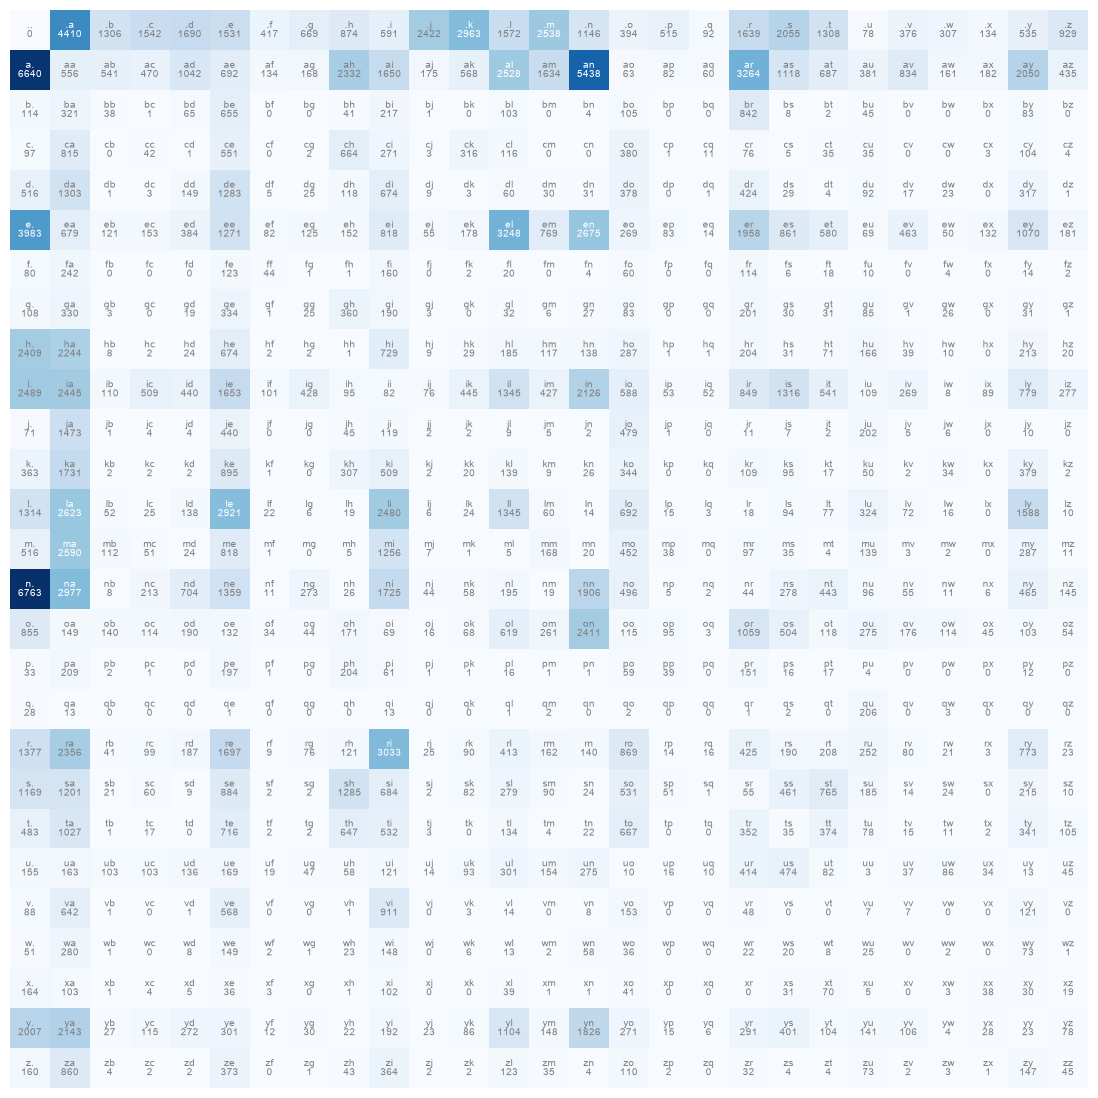

In [20]:
plt.figure(figsize=(14, 14))
plt.imshow(N, cmap="Blues")
for i in range(27):
    for j in range(27):
        color = "white" if N[i, j] > 2500 else "gray"  # 深色格子上用白字
        plt.text(j, i, itos[i] + itos[j], ha="center", va="bottom", color=color, fontsize=7)
        plt.text(j, i, N[i, j].item(), ha="center", va="top", color=color, fontsize=7)
plt.axis("off")
plt.show()
# 简单来说，就是形成了一张表，这个表里面有两个数据，一个是里面具体的两两配对的字符组合，另外一个就是这个字符组合出现了多少次。

**怎么读这张图**：
- 第一行（`.` 开头的那一行）是名字的首字母：a 开头最多，4410 次
- 第一列（后面跟 `.` 的那一列）是名字的尾字母：n 结尾最多，6763 次
- 左上角 `..` 是 0：没有空名字
- 颜色越深，次数越多；白色的格子是 0

**想一想**：找到 q 那一行（编号 17），它有什么特点？

<details><summary>答案</summary>

q 后面 206 次是 u，跟其他字母和结尾加起来一共只有 66 次。英语里 qu 几乎绑在一起，表格把这种规律直接数了出来。

</details>

**还剩的麻烦**：次数还不能直接拿来抽字母。a 那一行加起来有 33,885 次，我们要的是「a 后面跟 n 的**概率**」：5438 ÷ 33885 ≈ 16%。

## 第 5 步 · 次数变概率

**上一步留下的麻烦**：次数不是概率。**这一步的办法**：每一行除以这一行的总和，每行加起来就等于 1，变成概率。

**要用到的写法**：
- `N.float()`：整数变小数，不然除出来还是整数
- `F.sum(1)`：沿第 1 维加起来，也就是每一行各加成一个数，一共 27 个数
- `X.shape`：张量的形状

先按直觉写一遍，直接运行：

In [9]:
F = N.float()
row_sums = F.sum(1)    # 每一行的总和
P_wrong = F / row_sums  # 每一行除以这一行的总和？

print("row_sums 的形状:", row_sums.shape)
print("前 5 行各自加起来:", P_wrong.sum(1)[:5])

row_sums 的形状: torch.Size([27])
前 5 行各自加起来: tensor([7.0225, 4.4142, 0.2009, 0.3717, 0.4146])


**没报错，但每一行加起来都不是 1**：第一行是 7.02，第三行只有 0.20。程序照常跑完，只是悄悄算错了，这是最难发现的错误。错在哪？

<details><summary>提示 1</summary>

看形状：`F` 是 (27, 27)，`row_sums` 是 (27,)。形状不同的两个张量相除，PyTorch 会**广播**：从最右边的维度开始对齐，缺的维度当作 1，再复制补齐。

</details>

<details><summary>提示 2</summary>

(27,) 对齐 (27, 27) 时，被当成 (1, 27)：一行 27 个数，复制给每一行。于是第 j **列**的每个数，都除以了第 j 行的总和，方向反了。

</details>

<details><summary>答案</summary>

要让 `row_sums` 变成 (27, 1)：一列 27 个数，复制给每一列，这样第 i 行除以的才是第 i 行自己的总和。形状对了，广播的方向才对。

</details>

**TODO 3**：改一处，让 `row_sums` 的形状变成 (27, 1)。

**要用到的写法**：`F.sum(1, keepdim=True)`：一样是每一行加起来，但保留被加掉的那一维，形状是 (27, 1)，不是 (27,)。

In [21]:
# TODO 3：改一处，让 row_sums 的形状变成 (27, 1)
row_sums = F.sum(1,keepdim=True)
P = F / row_sums
print(P)
print("row_sums 的形状:", row_sums.shape)
print("前 5 行各自加起来:", P.sum(1)[:5])
assert torch.allclose(P.sum(1), torch.ones(27)), "先完成 TODO 3：每一行加起来应该等于 1"
print("名字以 a 开头的概率:", round(P[0, stoi["a"]].item(), 3))

tensor([[0.0000e+00, 1.3767e-01, 4.0770e-02, 4.8138e-02, 5.2758e-02, 4.7794e-02,
         1.3018e-02, 2.0885e-02, 2.7284e-02, 1.8450e-02, 7.5610e-02, 9.2498e-02,
         4.9074e-02, 7.9231e-02, 3.5776e-02, 1.2300e-02, 1.6077e-02, 2.8720e-03,
         5.1166e-02, 6.4153e-02, 4.0833e-02, 2.4350e-03, 1.1738e-02, 9.5839e-03,
         4.1832e-03, 1.6702e-02, 2.9001e-02],
        [1.9596e-01, 1.6408e-02, 1.5966e-02, 1.3870e-02, 3.0751e-02, 2.0422e-02,
         3.9546e-03, 4.9579e-03, 6.8821e-02, 4.8694e-02, 5.1645e-03, 1.6763e-02,
         7.4605e-02, 4.8222e-02, 1.6048e-01, 1.8592e-03, 2.4199e-03, 1.7707e-03,
         9.6326e-02, 3.2994e-02, 2.0274e-02, 1.1244e-02, 2.4613e-02, 4.7514e-03,
         5.3711e-03, 6.0499e-02, 1.2838e-02],
        [4.3100e-02, 1.2136e-01, 1.4367e-02, 3.7807e-04, 2.4575e-02, 2.4764e-01,
         0.0000e+00, 0.0000e+00, 1.5501e-02, 8.2042e-02, 3.7807e-04, 0.0000e+00,
         3.8941e-02, 0.0000e+00, 1.5123e-03, 3.9698e-02, 0.0000e+00, 0.0000e+00,
         3.1834e-

每一行都是 1 了。第一行就是「名字以各个字母开头」的概率，比如 a 开头约 13.8%。

**还剩的麻烦**：有了概率表，怎么用它来编名字？

## 第 6 步 · 照概率抽字母，编名字

**上一步留下的麻烦**：有了概率，还不会用。**这一步的办法**：从 `.`（编号 0）出发：

1. 查第 0 行，得到下一个字母的 27 个概率
2. 照这些概率抽一个，比如抽到 m（编号 13）
3. 再查第 13 行，抽下一个……
4. 抽到 `.` 就停

和第 2 步的瞎猜比，只改了一处：不再是 27 个符号机会均等，而是查表、照概率抽。

**要用到的写法**：
- `torch.multinomial(p, num_samples=1, replacement=True, generator=g)`：照概率 `p` 抽 1 个编号，返回只有一个数的张量。比如 `p` 是 `[0.1, 0.9]` 时，大约 9 成会抽到 1
- `.item()`：变成普通整数
- `torch.Generator().manual_seed(2147483647)`：固定随机数，每次运行抽到的都一样，方便和下面对答案

**TODO 4**：在循环里，取出第 `ix` 行的概率 `P[ix]`，照它抽下一个编号，存回 `ix`。

<details><summary>提示</summary>

`P[ix]` 是「当前字母后面跟各个符号」的 27 个概率，把它交给 `torch.multinomial`，别忘了 `.item()`。

</details>

<details><summary>答案</summary>

```python
ix = torch.multinomial(P[ix], num_samples=1, replacement=True, generator=g).item()
```

</details>

In [12]:
g = torch.Generator().manual_seed(2147483647)
for _ in range(10):
    out = []
    ix = 0  # 从开头记号 . 出发
    while True:
        # TODO 4：取出第 ix 行的概率 P[ix]，照它抽下一个编号，存回 ix
        ix = torch.multinomial(P[ix], num_samples=1, replacement=True, generator=g).item()


        assert ix is not None, "先完成 TODO 4"
        if ix == 0:  # 抽到结尾记号 .，这个名字结束
            break
        out.append(itos[ix])
    print("".join(out))

cexze
momasurailezitynn
konimittain
llayn
ka
da
staiyaubrtthrigotai
moliellavo
ke
teda


应该打印出 cexze、momasurailezitynn、konimittain……和开头的终点预告一样。

和第 2 步的乱码比：
- 长度正常多了：模型数到了「哪些字母后面常常就结束了」
- ka、da、ke、teda、llayn 挺像名字，但这 10 个没有一个是数据里原有的
- staiyaubrtthrigotai 还是怪：rt、tt、th、hr 单看都常见，连在一起就不像了。模型**只看前一个字母**，不知道更早的字母是什么

**还剩的麻烦**：「好多了」「还是怪」都是感觉。想改进模型，得有一个数说清楚它有多好，改完才知道有没有进步。

## 第 7 步 · 给模型打分：loss

**上一步留下的麻烦**：好坏只能凭感觉。**这一步的办法**：好的模型应该给**真实的名字**高概率。一个名字的概率，就是每一步猜中的概率乘起来。

直接运行：

In [22]:
def name_prob(w):
    prob = 1.0
    for a, b in bigrams(w):
        p = P[stoi[a], stoi[b]].item()
        print(f"  {a} → {b}：{p:.4f}")
        prob *= p
    return prob


for w in ["emma", "anna"]:
    print(w)
    print("  整个名字的概率:", name_prob(w))

emma
  . → e：0.0478
  e → m：0.0377
  m → m：0.0253
  m → a：0.3899
  a → .：0.1960
  整个名字的概率: 3.478213834606263e-06
anna
  . → a：0.1377
  a → n：0.1605
  n → n：0.1040
  n → a：0.1624
  a → .：0.1960
  整个名字的概率: 7.31395441343276e-05


emma 的概率约 0.0000035，anna 约 0.000073：模型觉得 anna 更像名字，高了约 21 倍。

那整个数据集 3 万多个名字，概率乘起来是多少？直接运行：

In [14]:
prob = 1.0
for w in words:
    for a, b in bigrams(w):
        prob *= P[stoi[a], stoi[b]].item()
print("整个数据集的概率:", prob)

整个数据集的概率: 0.0


**结果是 0。** 每个概率都小于 1，22 万多个乘起来，小到电脑里的小数存不下，就变成了 0，这叫**下溢**。不管模型好坏，算出来都是 0，就没法比了。

**办法：取对数**。log 把乘法变成加法：log(a × b) = log a + log b。22 万多个数加起来，不会变成 0。再做两处调整：

- 概率都小于 1，log 都是负数。取个负号变成正数，就**越小越好**，和阶段 1 的 loss 一样
- 除以 bigram 的个数，取平均。这样不管数据有多少，都能拿来比较

这个数叫**平均负对数似然**（negative log-likelihood，NLL）。「似然」就是模型给真实数据的概率。

**TODO 5**：在循环里，把 `torch.log(prob)` 加进 `log_likelihood`，再把 `n` 加 1。循环跑完，下面一行会取负号、求平均。

**要用到的写法**：`torch.log(x)`：自然对数，以 e 为底。`torch.log(torch.tensor(1.0))` 是 0。

<details><summary>提示</summary>

每个 bigram 做两件事：累加它的 log 概率，计数加 1。

</details>

<details><summary>答案</summary>

```python
log_likelihood += torch.log(prob)
n += 1
```

</details>

In [23]:
log_likelihood = 0.0
n = 0
for w in words:
    for a, b in bigrams(w):
        prob = P[stoi[a], stoi[b]]
        # TODO 5：把 log(prob) 加进 log_likelihood，再把 n 加 1
        log_likelihood += torch.log(prob)
        n += 1

assert n == 228146, "先完成 TODO 5：n 应该等于 bigram 的总数 228146"
nll = -log_likelihood / n  # 取负号、求平均
print(f"平均负对数似然（loss）= {float(nll):.4f}")

平均负对数似然（loss）= 2.4541


应该是 **2.4541**。

**想一想**：第 2 步那个瞎猜的模型，loss 是多少？

<details><summary>提示</summary>

瞎猜时，每一步猜中正确字母的概率是多少？

</details>

<details><summary>答案</summary>

每一步都是 1/27，所以 loss = −log(1/27) = log 27 ≈ **3.30**（可以运行 `math.log(27)` 验证）。数数的模型把 loss 从 3.30 降到 2.45，这就是「好多了」的具体数字。

</details>

**新的麻烦：没见过的组合**。随便编一个名字 andrejq，算算它的 loss。直接运行：

In [24]:
def name_nll(w):
    lls = [torch.log(P[stoi[a], stoi[b]]).item() for a, b in bigrams(w)]
    return -sum(lls) / len(lls)


print("emma 的 loss:", round(name_nll("emma"), 4))
print("andrejq 的 loss:", name_nll("andrejq"))

emma 的 loss: 2.5138
andrejq 的 loss: inf


andrejq 的 loss 是**无穷大**（inf）。数据里 j 后面从没出现过 q，表里那一格是 0，概率是 0，log 0 是负无穷。一个没见过的组合，就让整个名字变成「不可能」。可它只是少见，并不是不可能。

**办法：平滑**。每个格子先假装多见过 1 次，再算概率。直接运行：

In [17]:
P = (N + 1).float()
P /= P.sum(1, keepdim=True)

print("j → q 的概率:", P[stoi["j"], stoi["q"]].item())
print("andrejq 的 loss:", round(name_nll("andrejq"), 4))

total, n = 0.0, 0
for w in words:
    for a, b in bigrams(w):
        total += torch.log(P[stoi[a], stoi[b]]).item()
        n += 1
print("平滑后，整个数据集的 loss:", round(-total / n, 4))

j → q 的概率: 0.0003416467516217381
andrejq 的 loss: 3.4834
平滑后，整个数据集的 loss: 2.4546


andrejq 不再是无穷大了；整个数据集的 loss 从 2.4541 变成 2.4546，几乎没受影响。

**想一想**：把 `N + 1` 改成 `N + 1000`，会怎样？

<details><summary>提示</summary>

每个格子都多了 1000 次以后，次数少的格子和次数多的格子，差别还大吗？

</details>

<details><summary>答案</summary>

原来的差别被冲淡，每一行都接近平均分配，模型越来越像第 2 步的瞎猜，loss 会往 3.30 靠近（实测 2.85）。加多少是一个可以调的旋钮：加得越多，模型越「保守」。

</details>

## 跑完想一想

- 用你自己的英文名试试：`print(round(name_nll("你的名字"), 4))`，和 emma 的 2.51 比一比，模型觉得你的名字「像不像名字」？
- 第 6 步编出的 staiyaubrtthrigotai 为什么那么怪？如果让模型看前两个字母，会好吗？

## 还剩的麻烦：下一课

模型只看前一个字母，看得太短。可想多看几个字母，表就会爆炸：

| 看前面几个字母 | 表有多少格 |
|---|---|
| 1 个（这一课） | 27 × 27 = 729 |
| 2 个 | 27³ ≈ 2 万 |
| 3 个 | 27⁴ ≈ 53 万 |

数据只有 22 万多个 bigram，格子越多，大部分格子就越是 0，数不出可靠的概率。换成中文更夸张：常用汉字有几千个，光是只看前一个字的表，就有上千万格。

下一课用阶段 1 学的梯度下降，把这张表换成一个**神经网络**：输入前一个字母，输出下一个字母的 27 个概率。先让它学到和数数一样的结果（loss 约 2.45），再让它看更多字母。

## 这和大模型有什么关系

| | 这一课 | 大语言模型 |
|---|---|---|
| 猜什么 | 下一个字母 | 下一个 token |
| 看多少前文 | 1 个字母 | 几千到上百万个 token |
| 概率从哪来 | 数出来的表 | 神经网络算出来 |
| loss | 平均负对数似然 | 一样，也叫**交叉熵** |
| 怎么生成 | 照概率一个一个抽 | 一样（阶段 8 讲各种采样技巧） |

## 本课新词

| 词 | 意思 |
|---|---|
| 语言模型 | 给前面的内容，算出下一个字（token）的概率 |
| bigram | 相邻的两个字符；bigram 模型只看前一个字符 |
| 广播 | 形状不同的张量做运算时，PyTorch 自动复制补齐；形状对错决定方向对错 |
| 采样 | 照概率随机抽一个 |
| 似然 | 模型给真实数据的概率 |
| 负对数似然（NLL） | −log 似然，再取平均；越小越好，就是这一课的 loss |
| 交叉熵 | 大模型训练里对同一个 loss 的叫法 |
| 下溢 | 小数小到电脑存不下，变成 0 |
| 平滑 | 每个计数先加一点，让没见过的组合也有一点概率 |

阶段 2 的作业等第 2 课学完一起出。